# TimeXer: Transformers for Time Series Forecasting with Exogenous Variables

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/timexer_exogenous.ipynb)

**Paper**: *TimeXer: Empowering Transformers for Time Series Forecasting with Exogenous Variables* — Yuxuan Wang, Haixu Wu, Jiaxiang Dong, Guo Qin, Haoran Zhang, Yong Liu, Yunzhong Qiu, Jianmin Wang, Mingsheng Long. **NeurIPS 2024**. [arXiv:2402.19072](https://arxiv.org/abs/2402.19072)

**Official code**: [github.com/thuml/TimeXer](https://github.com/thuml/TimeXer)

**Key ideas**:
- **Endogenous series → patch tokens + a learnable global token.** The target series is cut into non-overlapping patches (temporal detail); one extra *global* token per endogenous variable summarises the whole series.
- **Exogenous series → variate tokens.** Each exogenous variable (and each calendar feature) is embedded as *one* token from its whole look-back window (iTransformer-style inverted embedding). This is robust to irregular / misaligned / missing exogenous data.
- **Endogenous self-attention** over `[patch tokens; global token]` captures temporal dependencies.
- **Exogenous-to-endogenous cross-attention**: only the **global token** queries the exogenous variate tokens, acting as a bridge that injects external information into the patch representations.
- A flatten head maps `(patch tokens + global token)` to the forecast.

This notebook re-implements TimeXer from scratch in PyTorch (faithful to the official code) and runs:
1. **Main (comparable) setting — features = M**: ETTh1, all 7 channels, lookback 96 → horizon 96. In this mode every channel is an endogenous series (own patch + global tokens) and the exogenous tokens are all 7 variates + 4 time-stamp features.
2. **Optional — features = MS** (the setting TimeXer was designed for): forecast **OT** using the other 6 channels as exogenous variables. Reported separately.

## Setup
No extra packages are needed on Colab (torch, numpy, pandas, matplotlib, sklearn are pre-installed).

In [1]:
import time, json, random, copy, math
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

SEED = 2024
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


## Data: ETTh1 with standard splits + calendar features

Standard Informer/Autoformer/TSLib borders, `StandardScaler` fitted on training rows only, metrics on scaled data.

TimeXer (like every TSLib model with `embed='timeF'`) also receives **time-stamp features** for the look-back window. For hourly data these are `[HourOfDay, DayOfWeek, DayOfMonth, DayOfYear]`, each scaled to $[-0.5, 0.5]$. In TimeXer they become **extra exogenous variate tokens**. `MarkedWindowDataset` wraps the shared `WindowDataset` and also returns the marks of the input window.

In [2]:
import numpy as np, pandas as pd, torch
from sklearn.preprocessing import StandardScaler
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])

In [3]:
L, H = 96, 96
n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24

def time_features_h(dates):
    # TSLib utils/timefeatures.py for freq='h' (timeenc=1)
    d = pd.DatetimeIndex(dates)
    return np.stack([d.hour / 23.0 - 0.5,
                     d.dayofweek / 6.0 - 0.5,
                     (d.day - 1) / 30.0 - 0.5,
                     (d.dayofyear - 1) / 365.0 - 0.5], axis=1).astype(np.float32)

dates = pd.to_datetime(pd.read_csv(URL, usecols=['date'])['date'])
marks_all = time_features_h(dates)
marks = {'train': marks_all[:n_tr],
         'val':   marks_all[n_tr - L: n_tr + n_va],
         'test':  marks_all[n_tr + n_va - L: n_tr + n_va + n_te]}

class MarkedWindowDataset(WindowDataset):
    """WindowDataset that also returns the time-stamp features of the look-back window."""
    def __init__(self, arr, mark, L, H, stride=1):
        super().__init__(arr, L, H, stride)
        self.mark = mark
    def __getitem__(self, k):
        x, y = super().__getitem__(k)
        i = self.idx[k]
        return x, torch.from_numpy(self.mark[i:i+self.L]), y

train, val, test, cols = load_etth1(L)
print('channels:', cols, '(OT is last)')
ds = {k: MarkedWindowDataset(a, marks[k], L, H) for k, a in [('train', train), ('val', val), ('test', test)]}
for k, d in ds.items(): print(f'{k:5s}: {len(d)} windows')
x, xm, y = ds['test'][0]; print('x', tuple(x.shape), 'x_mark', tuple(xm.shape), 'y', tuple(y.shape))

channels: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT'] (OT is last)
train: 8449 windows
val  : 2785 windows
test : 2785 windows
x (96, 7) x_mark (96, 4) y (96, 7)


## Attention building blocks

Standard multi-head scaled dot-product attention (TSLib `FullAttention` + `AttentionLayer`, no mask):
$$\mathrm{Attn}(Q,K,V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

In [4]:
class AttentionLayer(nn.Module):
    def __init__(self, d_model, n_heads, attention_dropout=0.1):
        super().__init__()
        d_keys = d_model // n_heads
        self.n_heads = n_heads
        self.query_projection = nn.Linear(d_model, d_keys * n_heads)
        self.key_projection = nn.Linear(d_model, d_keys * n_heads)
        self.value_projection = nn.Linear(d_model, d_keys * n_heads)
        self.out_projection = nn.Linear(d_keys * n_heads, d_model)
        self.dropout = nn.Dropout(attention_dropout)

    def forward(self, queries, keys, values):
        B, Lq, _ = queries.shape; _, S, _ = keys.shape; Hh = self.n_heads
        q = self.query_projection(queries).view(B, Lq, Hh, -1)
        k = self.key_projection(keys).view(B, S, Hh, -1)
        v = self.value_projection(values).view(B, S, Hh, -1)
        scale = 1.0 / math.sqrt(q.shape[-1])
        scores = torch.einsum('blhe,bshe->bhls', q, k)
        A = self.dropout(torch.softmax(scale * scores, dim=-1))
        out = torch.einsum('bhls,bshd->blhd', A, v).contiguous().view(B, Lq, -1)
        return self.out_projection(out)

## Embeddings

**Endogenous embedding (`EnEmbedding`)**: for each endogenous variable, split the look-back of length $L$ into $N = L/P$ non-overlapping patches of length $P=16$, project each with a bias-free linear layer, add sinusoidal positions, and append a learnable **global token** $\mathbf{G} \in \mathbb{R}^{d}$ (one per endogenous variable):
$$\mathbf{P}_{en} = \mathrm{PatchEmbed}(\mathbf{x}) + \mathrm{PE}, \qquad \mathbf{T}_{en} = [\mathbf{P}_{en};\ \mathbf{G}] \in \mathbb{R}^{(N+1)\times d}$$

**Exogenous embedding (`DataEmbedding_inverted`)**: each exogenous variable (and each calendar feature) becomes one **variate token** $\mathbf{V}_j = \mathrm{Linear}_{L\to d}(\mathbf{z}_j)$.

In [5]:
class PositionalEmbedding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).float().unsqueeze(1)
        div_term = (torch.arange(0, d_model, 2).float() * -(math.log(10000.0) / d_model)).exp()
        pe[:, 0::2] = torch.sin(position * div_term); pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))
    def forward(self, x):
        return self.pe[:, :x.size(1)]

class EnEmbedding(nn.Module):
    def __init__(self, n_vars, d_model, patch_len, dropout):
        super().__init__()
        self.patch_len = patch_len
        self.value_embedding = nn.Linear(patch_len, d_model, bias=False)
        self.glb_token = nn.Parameter(torch.randn(1, n_vars, 1, d_model))
        self.position_embedding = PositionalEmbedding(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):                                   # x: (B, n_vars, L)
        n_vars = x.shape[1]
        glb = self.glb_token.repeat((x.shape[0], 1, 1, 1))  # (B, n_vars, 1, d)
        x = x.unfold(dimension=-1, size=self.patch_len, step=self.patch_len)   # (B, n_vars, N, P)
        x = x.reshape(x.shape[0] * x.shape[1], x.shape[2], x.shape[3])
        x = self.value_embedding(x) + self.position_embedding(x)              # (B*n_vars, N, d)
        x = x.reshape(-1, n_vars, x.shape[-2], x.shape[-1])
        x = torch.cat([x, glb], dim=2)                                         # (B, n_vars, N+1, d)
        x = x.reshape(x.shape[0] * x.shape[1], x.shape[2], x.shape[3])
        return self.dropout(x), n_vars

class DataEmbedding_inverted(nn.Module):
    def __init__(self, c_in, d_model, dropout=0.1):
        super().__init__()
        self.value_embedding = nn.Linear(c_in, d_model)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x, x_mark):                           # x: (B, L, C), x_mark: (B, L, 4)
        x = x.permute(0, 2, 1)
        if x_mark is not None:
            x = torch.cat([x, x_mark.permute(0, 2, 1)], 1)  # calendar features become extra variate tokens
        return self.dropout(self.value_embedding(x))        # (B, C(+4), d)

## TimeXer encoder layer

For the endogenous tokens $\mathbf{T}_{en}$ of one variable and exogenous variate tokens $\mathbf{V}$:

1. **Endogenous self-attention** (patches ↔ patches ↔ global): $\hat{\mathbf{T}}_{en} = \mathrm{LN}(\mathbf{T}_{en} + \mathrm{SelfAttn}(\mathbf{T}_{en}))$
2. **Exogenous-to-endogenous cross-attention**, global token only: $\hat{\mathbf{G}} = \mathrm{LN}(\hat{\mathbf{G}} + \mathrm{CrossAttn}(\hat{\mathbf{G}}, \mathbf{V}))$
3. **Feed-forward** (two 1×1 convs) on all tokens: $\mathbf{T}' = \mathrm{LN}([\hat{\mathbf{P}};\hat{\mathbf{G}}] + \mathrm{FFN}([\hat{\mathbf{P}};\hat{\mathbf{G}}]))$

In features = M mode there are $D$ endogenous variables; their global tokens are stacked into a length-$D$ query sequence for the cross-attention (exactly as the official reshape does).

In [6]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff=None, dropout=0.1, activation='gelu'):
        super().__init__()
        d_ff = d_ff or 4 * d_model
        self.self_attention = AttentionLayer(d_model, n_heads, dropout)
        self.cross_attention = AttentionLayer(d_model, n_heads, dropout)
        self.conv1 = nn.Conv1d(d_model, d_ff, kernel_size=1)
        self.conv2 = nn.Conv1d(d_ff, d_model, kernel_size=1)
        self.norm1, self.norm2, self.norm3 = nn.LayerNorm(d_model), nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        self.activation = F.relu if activation == 'relu' else F.gelu

    def forward(self, x, cross):
        # x: (B*n_vars, N+1, d) endogenous tokens; cross: (B, C_ex, d) exogenous variate tokens
        B, _, D = cross.shape
        x = self.norm1(x + self.dropout(self.self_attention(x, x, x)))           # 1. self-attention
        x_glb_ori = x[:, -1, :].unsqueeze(1)                                      # global tokens (B*n_vars, 1, d)
        x_glb = x_glb_ori.reshape(B, -1, D)                                       # (B, n_vars, d)
        x_glb_attn = self.dropout(self.cross_attention(x_glb, cross, cross))     # 2. cross-attention to exogenous
        x_glb_attn = x_glb_attn.reshape(-1, D).unsqueeze(1)
        x_glb = self.norm2(x_glb_ori + x_glb_attn)
        y = x = torch.cat([x[:, :-1, :], x_glb], dim=1)
        y = self.dropout(self.activation(self.conv1(y.transpose(-1, 1))))        # 3. FFN
        y = self.dropout(self.conv2(y).transpose(-1, 1))
        return self.norm3(x + y)

## Full model

- **Instance normalisation** (Non-stationary Transformer style) of every input channel, de-normalised with the endogenous channel statistics.
- `features='M'`: all $D$ channels are endogenous (each gets its own patch + global tokens, with shared weights), and the exogenous tokens are all $D$ variates + 4 calendar features.
- `features='MS'`: the last channel (OT) is endogenous; the other $D-1$ channels + 4 calendar features are exogenous.
- **Flatten head**: $(N+1)\cdot d \rightarrow H$ per endogenous variable.

In [7]:
class TimeXer(nn.Module):
    def __init__(self, features='M', seq_len=96, pred_len=96, enc_in=7, d_model=256, n_heads=8, e_layers=1,
                 d_ff=2048, patch_len=16, dropout=0.1, activation='gelu', use_norm=True):
        super().__init__()
        self.features, self.pred_len, self.use_norm = features, pred_len, use_norm
        self.patch_num = seq_len // patch_len
        self.n_vars = 1 if features == 'MS' else enc_in
        self.en_embedding = EnEmbedding(self.n_vars, d_model, patch_len, dropout)
        self.ex_embedding = DataEmbedding_inverted(seq_len, d_model, dropout)
        self.layers = nn.ModuleList([EncoderLayer(d_model, n_heads, d_ff, dropout, activation) for _ in range(e_layers)])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Sequential(nn.Flatten(start_dim=-2), nn.Linear(d_model * (self.patch_num + 1), pred_len),
                                  nn.Dropout(dropout))

    def forward(self, x_enc, x_mark):
        if self.use_norm:
            means = x_enc.mean(1, keepdim=True).detach()
            x_enc = x_enc - means
            stdev = torch.sqrt(torch.var(x_enc, dim=1, keepdim=True, unbiased=False) + 1e-5)
            x_enc = x_enc / stdev
        if self.features == 'MS':
            en_embed, n_vars = self.en_embedding(x_enc[:, :, -1:].permute(0, 2, 1))   # endogenous: OT only
            ex_embed = self.ex_embedding(x_enc[:, :, :-1], x_mark)                    # exogenous: other channels
        else:
            en_embed, n_vars = self.en_embedding(x_enc.permute(0, 2, 1))              # every channel endogenous
            ex_embed = self.ex_embedding(x_enc, x_mark)                               # all variates as exogenous tokens
        enc_out = en_embed
        for layer in self.layers:
            enc_out = layer(enc_out, ex_embed)
        enc_out = self.norm(enc_out)
        enc_out = enc_out.reshape(-1, n_vars, enc_out.shape[-2], enc_out.shape[-1]).permute(0, 1, 3, 2)  # (B, n_vars, d, N+1)
        dec_out = self.head(enc_out).permute(0, 2, 1)                                  # (B, H, n_vars)
        if self.use_norm:
            if self.features == 'MS':
                dec_out = dec_out * stdev[:, :, -1:] + means[:, :, -1:]
            else:
                dec_out = dec_out * stdev + means
        return dec_out

m = TimeXer('M', d_model=256, d_ff=2048, e_layers=1)
print('TimeXer (M):', sum(p.numel() for p in m.parameters()), 'parameters')
with torch.no_grad():
    print('output:', tuple(m(torch.randn(2, L, 7), torch.randn(2, L, 4)).shape))

TimeXer (M): 1782112 parameters
output: (2, 96, 7)


## Training (official hyper-parameters)

From `scripts/multivariate/ETT/TimeXer_ETTh1.sh` (pred_len 96) and `run.py` defaults:

| | features = M (main) | features = MS (optional) |
|---|---|---|
| d_model / d_ff / e_layers | 256 / 2048 / 1 | 512 / 512 / 2 |
| heads, patch_len, dropout, activation | 8, 16, 0.1, gelu | 8, 16, 0.1, gelu |
| batch size | 4 | 32 |
| optimizer | Adam, lr 1e-4 | Adam, lr 1e-4 |
| lr schedule | `type1`: halve every epoch | same |
| epochs / patience | 10 / 3 (early stopping on val MSE) | 10 / 3 |
| loss | MSE (all channels) | MSE on OT only |

In [8]:
def evaluate(model, loader, target_only=False):
    model.eval(); se = ae = n = 0.0
    with torch.no_grad():
        for x, xm, y in loader:
            x, xm, y = x.to(device), xm.to(device), y.to(device)
            p = model(x, xm)
            if target_only: y = y[:, :, -1:]
            se += ((p - y) ** 2).sum().item(); ae += (p - y).abs().sum().item(); n += y.numel()
    return se / n, ae / n

def predict(model, loader):
    model.eval(); P = []
    with torch.no_grad():
        for x, xm, y in loader:
            P.append(model(x.to(device), xm.to(device)).cpu().numpy())
    return np.concatenate(P)

def train_timexer(features, cfg, batch_size, lr=1e-4, epochs=10, patience=3):
    seed_everything()
    target_only = features == 'MS'
    g = torch.Generator(); g.manual_seed(SEED)
    tr_loader = DataLoader(ds['train'], batch_size=batch_size, shuffle=True, generator=g)
    va_loader = DataLoader(ds['val'], batch_size=256, shuffle=False)
    model = TimeXer(features, L, H, 7, **cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.MSELoss()
    best, best_state, bad = float('inf'), None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); losses = []
        for x, xm, y in tr_loader:
            x, xm, y = x.to(device), xm.to(device), y.to(device)
            if target_only: y = y[:, :, -1:]
            opt.zero_grad(); loss = crit(model(x, xm), y); loss.backward(); opt.step()
            losses.append(loss.item())
        vmse, _ = evaluate(model, va_loader, target_only)
        flag = ''
        if vmse < best:
            best, best_state, bad, flag = vmse, copy.deepcopy(model.state_dict()), 0, '*'
        else:
            bad += 1
        print(f'[{features}] epoch {ep:2d} | train {np.mean(losses):.4f} | val {vmse:.4f} {flag} | {time.time()-t0:.0f}s')
        if bad >= patience:
            print('early stopping'); break
        for gp in opt.param_groups: gp['lr'] = lr * (0.5 ** ep)    # TSLib lradj='type1'
    model.load_state_dict(best_state)
    return model, time.time() - t0

## Main run: features = M (ETTh1 96 → 96, all 7 channels)

In [9]:
te_loader = DataLoader(ds['test'], batch_size=256, shuffle=False)
cfg_M = dict(d_model=256, n_heads=8, e_layers=1, d_ff=2048, patch_len=16, dropout=0.1)
model_M, secs_M = train_timexer('M', cfg_M, batch_size=4)
mse_M, mae_M = evaluate(model_M, te_loader)
params_M = sum(p.numel() for p in model_M.parameters())
print(f'==> TimeXer (M): test MSE {mse_M:.4f}  MAE {mae_M:.4f}  | {params_M:,} params | {secs_M:.0f}s')

[M] epoch  1 | train 0.3980 | val 0.6982 * | 15s


[M] epoch  2 | train 0.3698 | val 0.6989  | 34s


[M] epoch  3 | train 0.3587 | val 0.6888 * | 44s


[M] epoch  4 | train 0.3530 | val 0.6874 * | 48s


[M] epoch  5 | train 0.3505 | val 0.6861 * | 53s


[M] epoch  6 | train 0.3488 | val 0.6839 * | 57s


[M] epoch  7 | train 0.3484 | val 0.6837 * | 62s


[M] epoch  8 | train 0.3480 | val 0.6849  | 66s


[M] epoch  9 | train 0.3485 | val 0.6844  | 79s


[M] epoch 10 | train 0.3477 | val 0.6844  | 100s
early stopping
==> TimeXer (M): test MSE 0.3859  MAE 0.4020  | 1,782,112 params | 100s


## Optional: features = MS — forecast OT with 6 exogenous channels

This is the scenario TimeXer was built for (paper Appendix I.3, "long-term forecasting with exogenous variables": last column = endogenous target, other columns = exogenous). Only OT is predicted, so the numbers are **not** comparable to the 7-channel M results above (OT alone is much easier: paper reports 0.057 MSE). Official config: `scripts/forecast_exogenous/ETTh1/TimeXer.sh` (pred_len 96).

In [10]:
RUN_MS = True
if RUN_MS:
    cfg_MS = dict(d_model=512, n_heads=8, e_layers=2, d_ff=512, patch_len=16, dropout=0.1)
    model_MS, secs_MS = train_timexer('MS', cfg_MS, batch_size=32)
    mse_MS, mae_MS = evaluate(model_MS, te_loader, target_only=True)
    params_MS = sum(p.numel() for p in model_MS.parameters())
    print(f'==> TimeXer (MS, OT target): test MSE {mse_MS:.4f}  MAE {mae_MS:.4f}  | {params_MS:,} params | {secs_MS:.0f}s')

[MS] epoch  1 | train 0.1751 | val 0.1042 * | 2s


[MS] epoch  2 | train 0.1626 | val 0.1220  | 4s


[MS] epoch  3 | train 0.1566 | val 0.1068  | 5s


[MS] epoch  4 | train 0.1518 | val 0.1081  | 7s
early stopping
==> TimeXer (MS, OT target): test MSE 0.0571  MAE 0.1816  | 5,662,816 params | 7s


## Forecast plot (OT channel)

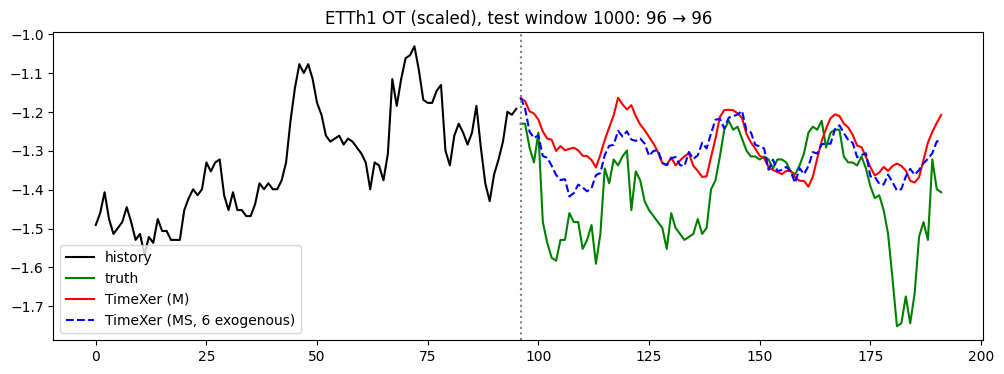

In [11]:
P_M = predict(model_M, te_loader)
k, ot = 1000, cols.index('OT')
X, _, Y = ds['test'][k]
t_in, t_out = np.arange(L), np.arange(L, L + H)
plt.figure(figsize=(12, 4))
plt.plot(t_in, X[:, ot], 'k', label='history')
plt.plot(t_out, Y[:, ot], 'g', label='truth')
plt.plot(t_out, P_M[k, :, ot], 'r', label='TimeXer (M)')
if RUN_MS:
    P_MS = predict(model_MS, te_loader)
    plt.plot(t_out, P_MS[k, :, 0], 'b--', label='TimeXer (MS, 6 exogenous)')
plt.axvline(L, color='gray', ls=':')
plt.title(f'ETTh1 OT (scaled), test window {k}: {L} → {H}'); plt.legend(); plt.show()

## Results

Test set: all 2785 stride-1 windows; MSE/MAE averaged over windows × horizon × channels (scaled data). Paper numbers: M from Table 12 (full multivariate results, L = 96, H = 96); MS from Table 11 (full results of long-term forecasting with exogenous variables, ETTh1, H = 96).

In [12]:
PAPER_M, PAPER_MS = (0.382, 0.403), (0.057, 0.181)
print(f"{'setting':28s} {'MSE':>7s} {'MAE':>7s}   {'paper MSE':>9s} {'paper MAE':>9s}   train s")
print(f"{'TimeXer M (7 ch)':28s} {mse_M:7.4f} {mae_M:7.4f}   {PAPER_M[0]:9.3f} {PAPER_M[1]:9.3f}   {secs_M:.0f}")
if RUN_MS:
    print(f"{'TimeXer MS (OT, 6 exog.)':28s} {mse_MS:7.4f} {mae_MS:7.4f}   {PAPER_MS[0]:9.3f} {PAPER_MS[1]:9.3f}   {secs_MS:.0f}")
print('\nReference (TSLib, ETTh1 96→96, M): DLinear 0.386/0.400, PatchTST 0.414/0.419, iTransformer 0.386/0.405, TimesNet 0.384/0.402')

out = {
    'model': 'TimeXer',
    'paper': 'TimeXer: Empowering Transformers for Time Series Forecasting with Exogenous Variables (arXiv 2402.19072)',
    'venue': 'NeurIPS 2024',
    'type': 'supervised',
    'lookback': L, 'horizon': H,
    'mse': mse_M, 'mae': mae_M,
    'paper_mse': PAPER_M[0], 'paper_mae': PAPER_M[1],
    'params': params_M,
    'train_or_infer_seconds': secs_M,
    'notes': ('features=M, all 7 channels endogenous, exogenous tokens = 7 variates + 4 timeF calendar features (official M mode). '
              'Official ETTh1-96 config: d_model 256, d_ff 2048, e_layers 1, 8 heads, patch 16, batch 4, Adam 1e-4, type1 lr, '
              '10 epochs, patience 3. Single seed 2024. Stride-1 test (2785 windows).'),
}
if RUN_MS:
    out['ms_setting'] = dict(target='OT', exogenous='HUFL,HULL,MUFL,MULL,LUFL,LULL + 4 calendar features',
                             mse=mse_MS, mae=mae_MS, paper_mse=PAPER_MS[0], paper_mae=PAPER_MS[1],
                             params=params_MS, train_seconds=secs_MS,
                             note='metrics on OT only (scaled); not comparable to the 7-channel M numbers')
try:
    with open('results_timexer_exogenous.json', 'w') as f: json.dump(out, f, indent=2)
    print('saved results_timexer_exogenous.json')
except Exception as e:
    print('could not save results:', e)

setting                          MSE     MAE   paper MSE paper MAE   train s
TimeXer M (7 ch)              0.3859  0.4020       0.382     0.403   100
TimeXer MS (OT, 6 exog.)      0.0571  0.1816       0.057     0.181   7

Reference (TSLib, ETTh1 96→96, M): DLinear 0.386/0.400, PatchTST 0.414/0.419, iTransformer 0.386/0.405, TimesNet 0.384/0.402
saved results_timexer_exogenous.json


## Using your own data

1. **Arrange columns so the target(s) are last** and build a `(T, D)` float array; split chronologically and scale with training statistics (replace `load_etth1`).
2. **Exogenous-variable forecasting (`features='MS'`)**: the last column is the endogenous target; all other columns are exogenous drivers (e.g. weather forecasts, prices, load). They only need to cover the look-back window — TimeXer embeds each one as a single variate token, so they may be noisy or on a different sampling grid if you resample them to length $L$.
3. **Multivariate forecasting (`features='M'`)**: every column is forecast; all columns also act as exogenous tokens.
4. Provide calendar features for each step via `time_features_h` (or pass `x_mark=None` to the embedding if you have no timestamps — then remove the `+4` tokens).
5. `L` must be divisible by `patch_len` (16 by default). Adjust `enc_in`, `d_model`, `e_layers` and batch size to your data size.